In [1]:
print("Hello! My Data Science 500 project is starting.")
print("Book Market Analytics")

Hello! My Data Science 500 project is starting.
Book Market Analytics


In [2]:

# Install the libraries required for the project
!pip install beautifulsoup4 requests pandas matplotlib seaborn scikit-learn


In [3]:

import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from sklearn.linear_model import LinearRegression

print("All required libraries are ready!")


All required libraries are ready!


In [4]:

import requests
from bs4 import BeautifulSoup

url = "https://books.toscrape.com/"
response = requests.get(url, timeout=30)

print("Website status code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")

print("Website title:", soup.title.get_text(strip=True))
print("Books found on the first page:", len(soup.select("article.product_pod")))


Website status code: 200
Website title: All products | Books to Scrape - Sandbox
Books found on the first page: 20


In [5]:

import requests
import pandas as pd
import time
from bs4 import BeautifulSoup
from urllib.parse import urljoin

base_url = "https://books.toscrape.com/"
session = requests.Session()

books = []

for page_number in range(1, 11):
    if page_number == 1:
        page_url = base_url
    else:
        page_url = urljoin(
            base_url, f"catalogue/page-{page_number}.html"
        )

    response = session.get(page_url, timeout=30)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    book_cards = soup.select("article.product_pod")

    for card in book_cards:
        title = card.h3.a["title"]
        price_text = card.select_one(".price_color").get_text(strip=True)
        price = float(price_text.replace("£", "").replace("Â", ""))

        rating_classes = card.select_one(".star-rating")["class"]
        rating_word = next(
            word for word in rating_classes
            if word != "star-rating"
        )

        rating_map = {
            "One": 1, "Two": 2, "Three": 3,
            "Four": 4, "Five": 5
        }

        book_url = urljoin(page_url, card.h3.a["href"])

        # Visit the individual book page for stock information
        detail_response = session.get(book_url, timeout=30)
        detail_response.raise_for_status()

        detail_soup = BeautifulSoup(
            detail_response.text, "html.parser"
        )

        availability_text = detail_soup.select_one(
            ".product_main .availability"
        ).get_text(" ", strip=True)

        import re
        quantity_match = re.search(
            r"\((\d+)\s+available\)", availability_text
        )

        quantity = (
            int(quantity_match.group(1))
            if quantity_match else None
        )

        stock_status = (
            "In stock" if "In stock" in availability_text
            else "Out of stock"
        )

        books.append({
            "title": title,
            "price_gbp": price,
            "rating_word": rating_word,
            "rating": rating_map[rating_word],
            "stock_status": stock_status,
            "stock_quantity": quantity,
            "book_url": book_url
        })

    print(
        f"Page {page_number}/10 completed. "
        f"Total books collected: {len(books)}"
    )

    time.sleep(0.2)

# Create a DataFrame from the collected books
df = pd.DataFrame(books)

print("\nScraping completed!")
print("Total books collected:", len(df))

df.head()


Page 1/10 completed. Total books collected: 20
Page 2/10 completed. Total books collected: 40
Page 3/10 completed. Total books collected: 60
Page 4/10 completed. Total books collected: 80
Page 5/10 completed. Total books collected: 100
Page 6/10 completed. Total books collected: 120
Page 7/10 completed. Total books collected: 140
Page 8/10 completed. Total books collected: 160
Page 9/10 completed. Total books collected: 180
Page 10/10 completed. Total books collected: 200

Scraping completed!
Total books collected: 200


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,book_url
0,A Light in the Attic,51.77,Three,3,In stock,22,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,1,In stock,20,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,1,In stock,20,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,4,In stock,20,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,20,https://books.toscrape.com/catalogue/sapiens-a...


In [6]:

df.to_csv("books_dataset.csv", index=False)

print("Dataset saved successfully!")
print("Dataset dimensions:", df.shape)

df.head(10)


Dataset saved successfully!
Dataset dimensions: (200, 7)


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,book_url
0,A Light in the Attic,51.77,Three,3,In stock,22,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,1,In stock,20,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,1,In stock,20,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,4,In stock,20,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,20,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,22.65,One,1,In stock,19,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,33.34,Four,4,In stock,19,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,17.93,Three,3,In stock,19,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,22.60,Four,4,In stock,19,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,52.15,One,1,In stock,19,https://books.toscrape.com/catalogue/the-black...


In [7]:

import requests
import pandas as pd
import time
from bs4 import BeautifulSoup
from urllib.parse import urljoin

base_url = "https://books.toscrape.com/"
session = requests.Session()

books = []

for page_number in range(1, 11):
    if page_number == 1:
        page_url = base_url
    else:
        page_url = urljoin(
            base_url, f"catalogue/page-{page_number}.html"
        )

    response = session.get(page_url, timeout=30)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    book_cards = soup.select("article.product_pod")

    for card in book_cards:
        title = card.h3.a["title"]
        price_text = card.select_one(".price_color").get_text(strip=True)
        price = float(price_text.replace("£", "").replace("Â", ""))

        rating_classes = card.select_one(".star-rating")["class"]
        rating_word = next(
            word for word in rating_classes
            if word != "star-rating"
        )

        rating_map = {
            "One": 1, "Two": 2, "Three": 3,
            "Four": 4, "Five": 5
        }

        book_url = urljoin(page_url, card.h3.a["href"])

        # Visit the individual book page for stock information
        detail_response = session.get(book_url, timeout=30)
        detail_response.raise_for_status()

        detail_soup = BeautifulSoup(
            detail_response.text, "html.parser"
        )

        availability_text = detail_soup.select_one(
            ".product_main .availability"
        ).get_text(" ", strip=True)

        import re
        quantity_match = re.search(
            r"\((\d+)\s+available\)", availability_text
        )

        quantity = (
            int(quantity_match.group(1))
            if quantity_match else None
        )

        stock_status = (
            "In stock" if "In stock" in availability_text
            else "Out of stock"
        )

        books.append({
            "title": title,
            "price_gbp": price,
            "rating_word": rating_word,
            "rating": rating_map[rating_word],
            "stock_status": stock_status,
            "stock_quantity": quantity,
            "book_url": book_url
        })

    print(
        f"Page {page_number}/10 completed. "
        f"Total books collected: {len(books)}"
    )

    time.sleep(0.2)

# Create a DataFrame from the collected books
df = pd.DataFrame(books)

print("\nScraping completed!")
print("Total books collected:", len(df))

df.head()



Page 1/10 completed. Total books collected: 20
Page 2/10 completed. Total books collected: 40
Page 3/10 completed. Total books collected: 60
Page 4/10 completed. Total books collected: 80
Page 5/10 completed. Total books collected: 100
Page 6/10 completed. Total books collected: 120
Page 7/10 completed. Total books collected: 140
Page 8/10 completed. Total books collected: 160
Page 9/10 completed. Total books collected: 180
Page 10/10 completed. Total books collected: 200

Scraping completed!
Total books collected: 200


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,book_url
0,A Light in the Attic,51.77,Three,3,In stock,22,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,1,In stock,20,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,1,In stock,20,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,4,In stock,20,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,20,https://books.toscrape.com/catalogue/sapiens-a...


In [8]:

# Save the scraped book data
df.to_csv("books_dataset.csv", index=False)

# Check the dataset
print("Total books:", len(df))
print("Number of columns:", len(df.columns))
print("\nColumn names:")
print(df.columns.tolist())

# Download the CSV file to your computer
from google.colab import files
files.download("books_dataset.csv")


Total books: 200
Number of columns: 7

Column names:
['title', 'price_gbp', 'rating_word', 'rating', 'stock_status', 'stock_quantity', 'book_url']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

import pandas as pd

# Load the downloaded dataset
df = pd.read_csv("books_dataset.csv")

# Display the first five books
print("First five books:")
display(df.head())

# Check the size of the dataset
print("Dataset dimensions:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())


First five books:


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,book_url
0,A Light in the Attic,51.77,Three,3,In stock,22,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,1,In stock,20,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,1,In stock,20,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,4,In stock,20,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,20,https://books.toscrape.com/catalogue/sapiens-a...


Dataset dimensions: (200, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   title           200 non-null    object 
 1   price_gbp       200 non-null    float64
 2   rating_word     200 non-null    object 
 3   rating          200 non-null    int64  
 4   stock_status    200 non-null    object 
 5   stock_quantity  200 non-null    int64  
 6   book_url        200 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 11.1+ KB

Missing values:
title             0
price_gbp         0
rating_word       0
rating            0
stock_status      0
stock_quantity    0
book_url          0
dtype: int64

Duplicate rows: 0


In [10]:

# Make a copy so the original data remains unchanged
clean_df = df.copy()

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Standardise book titles
clean_df["title"] = clean_df["title"].astype("string").str.strip()

# Convert prices to numeric values
clean_df["price_gbp"] = pd.to_numeric(
    clean_df["price_gbp"], errors="coerce"
)

# Convert ratings to numeric values
clean_df["rating"] = pd.to_numeric(
    clean_df["rating"], errors="coerce"
)

# Clean and standardise stock status
clean_df["stock_status"] = (
    clean_df["stock_status"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Convert stock quantities to numeric values
clean_df["stock_quantity"] = pd.to_numeric(
    clean_df["stock_quantity"], errors="coerce"
)

# Remove records missing essential information
clean_df = clean_df.dropna(
    subset=["title", "price_gbp", "rating", "stock_status"]
)

# Keep only valid prices and ratings
clean_df = clean_df[
    (clean_df["price_gbp"] > 0) &
    (clean_df["rating"].between(1, 5))
].copy()

# Reset row numbering
clean_df = clean_df.reset_index(drop=True)

print("Original number of rows:", len(df))
print("Cleaned number of rows:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())

display(clean_df.head())


Original number of rows: 200
Cleaned number of rows: 200
Rows removed: 0

Missing values after cleaning:
title             0
price_gbp         0
rating_word       0
rating            0
stock_status      0
stock_quantity    0
book_url          0
dtype: int64


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,book_url
0,A Light in the Attic,51.77,Three,3,In Stock,22,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,1,In Stock,20,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,1,In Stock,20,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,4,In Stock,20,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In Stock,20,https://books.toscrape.com/catalogue/sapiens-a...


In [11]:

# Save the cleaned dataset
clean_df.to_csv("books_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Number of books:", len(clean_df))

# Download the cleaned dataset
from google.colab import files
files.download("books_cleaned.csv")


Cleaned dataset saved successfully!
Number of books: 200


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

# Create a copy of the original dataset
clean_df = df.copy()

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Clean the text fields
clean_df["title"] = clean_df["title"].astype("string").str.strip()
clean_df["stock_status"] = (
    clean_df["stock_status"].astype("string").str.strip().str.title()
)

# Convert numeric columns
clean_df["price_gbp"] = pd.to_numeric(
    clean_df["price_gbp"], errors="coerce"
)
clean_df["rating"] = pd.to_numeric(
    clean_df["rating"], errors="coerce"
)
clean_df["stock_quantity"] = pd.to_numeric(
    clean_df["stock_quantity"], errors="coerce"
)

# Remove rows with missing essential information
clean_df = clean_df.dropna(
    subset=["title", "price_gbp", "rating", "stock_status"]
)

# Remove invalid prices and ratings
clean_df = clean_df[
    (clean_df["price_gbp"] > 0) &
    (clean_df["rating"].between(1, 5))
].copy()

clean_df.reset_index(drop=True, inplace=True)

# Display the cleaning results
print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))
print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())

display(clean_df.head())


Original rows: 200
Cleaned rows: 200
Rows removed: 0

Missing values after cleaning:
title             0
price_gbp         0
rating_word       0
rating            0
stock_status      0
stock_quantity    0
book_url          0
dtype: int64


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,book_url
0,A Light in the Attic,51.77,Three,3,In Stock,22,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,1,In Stock,20,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,1,In Stock,20,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,4,In Stock,20,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In Stock,20,https://books.toscrape.com/catalogue/sapiens-a...


In [13]:

clean_df.to_csv("books_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

from google.colab import files
files.download("books_cleaned.csv")


Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

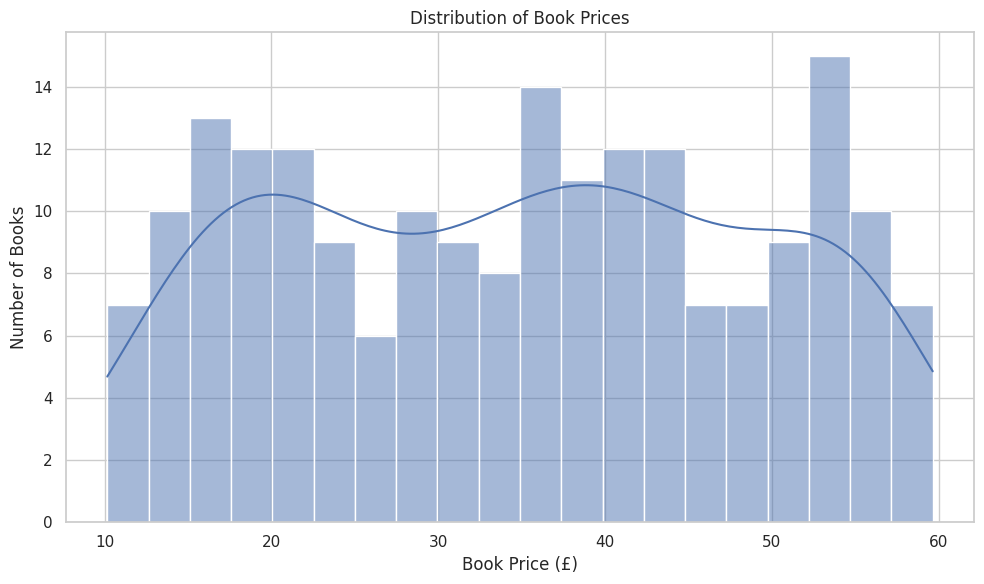

In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(data=clean_df, x="price_gbp", bins=20, kde=True)

plt.title("Distribution of Book Prices")
plt.xlabel("Book Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()


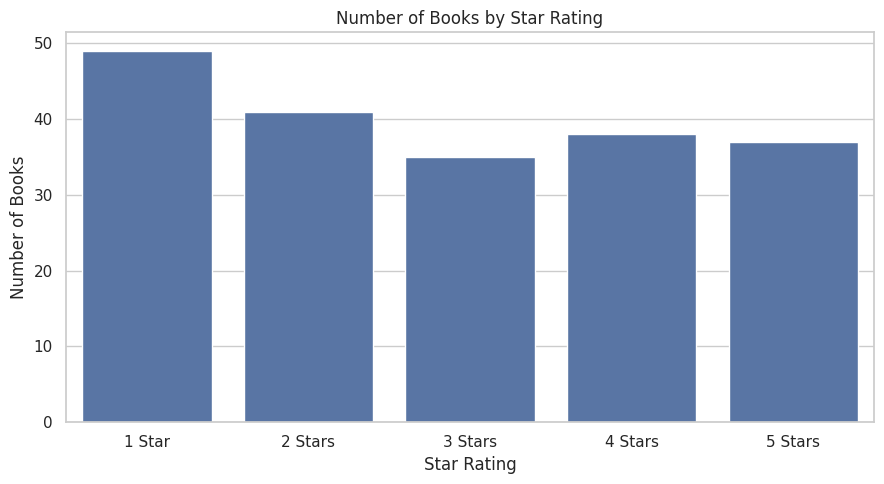

Book counts by rating:
rating
1    49
2    41
3    35
4    38
5    37
Name: count, dtype: int64


In [15]:

# Count books in each star-rating category
rating_counts = (
    clean_df["rating"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .sort_index()
)

plt.figure(figsize=(9, 5))
sns.barplot(x=rating_counts.index, y=rating_counts.values)

plt.title("Number of Books by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.xticks([0, 1, 2, 3, 4], ["1 Star", "2 Stars", "3 Stars", "4 Stars", "5 Stars"])
plt.tight_layout()
plt.show()

print("Book counts by rating:")
print(rating_counts)


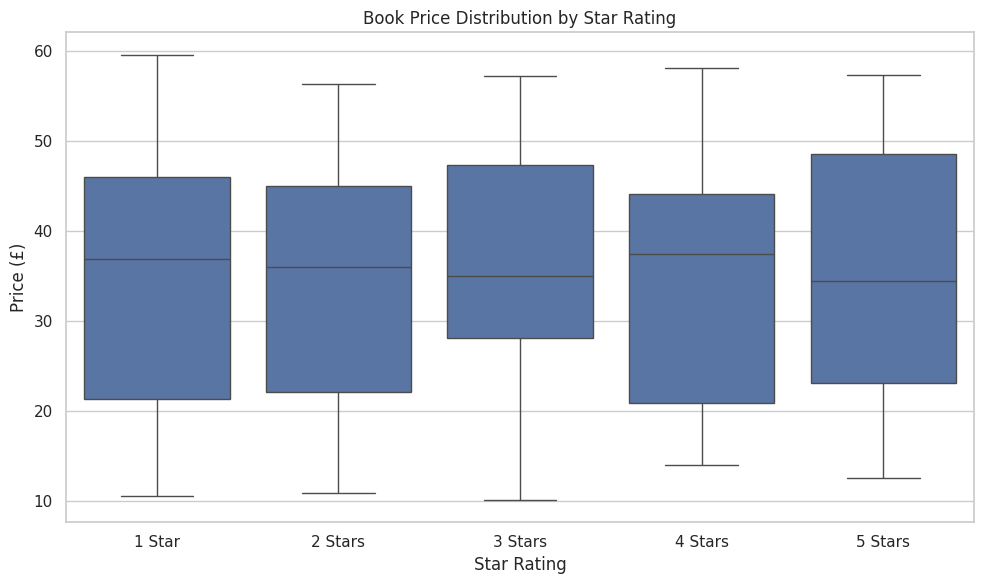

Average price by rating:
rating
1    34.59
2    33.74
3    36.19
4    34.90
5    34.82
Name: price_gbp, dtype: float64

Median price by rating:
rating
1    36.94
2    36.00
3    35.07
4    37.44
5    34.53
Name: price_gbp, dtype: float64


In [16]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=clean_df,
    x="rating",
    y="price_gbp"
)

plt.title("Book Price Distribution by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Price (£)")
plt.xticks([0, 1, 2, 3, 4], ["1 Star", "2 Stars", "3 Stars", "4 Stars", "5 Stars"])
plt.tight_layout()
plt.show()

print("Average price by rating:")
print(clean_df.groupby("rating")["price_gbp"].mean().round(2))

print("\nMedian price by rating:")
print(clean_df.groupby("rating")["price_gbp"].median().round(2))


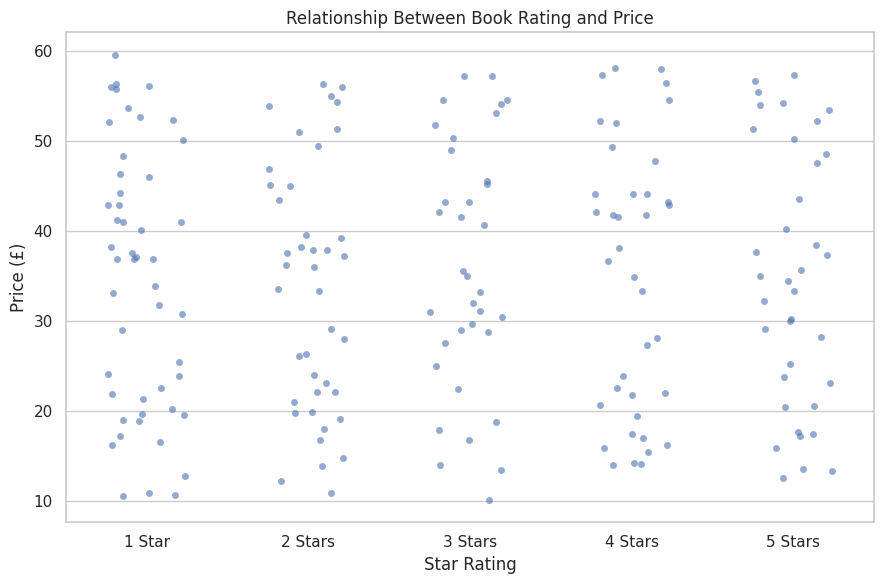

Correlation between rating and price: 0.017


In [17]:

plt.figure(figsize=(9, 6))

sns.stripplot(
    data=clean_df,
    x="rating",
    y="price_gbp",
    jitter=0.25,
    alpha=0.6
)

plt.title("Relationship Between Book Rating and Price")
plt.xlabel("Star Rating")
plt.ylabel("Price (£)")
plt.xticks([0, 1, 2, 3, 4], ["1 Star", "2 Stars", "3 Stars", "4 Stars", "5 Stars"])
plt.tight_layout()
plt.show()

print(
    "Correlation between rating and price:",
    round(clean_df["rating"].corr(clean_df["price_gbp"]), 3)
)


In [18]:

# Summary statistics for your report

print("1. PRICE SUMMARY")
print(clean_df["price_gbp"].describe().round(2))

print("\n2. BOOK COUNTS BY RATING")
print(clean_df["rating"].value_counts().sort_index())

print("\n3. AVERAGE PRICE BY RATING")
print(clean_df.groupby("rating")["price_gbp"].mean().round(2))

print("\n4. MEDIAN PRICE BY RATING")
print(clean_df.groupby("rating")["price_gbp"].median().round(2))

print("\n5. PRICE-RATING CORRELATION")
print(round(clean_df["rating"].corr(clean_df["price_gbp"]), 3))


1. PRICE SUMMARY
count    200.00
mean      34.80
std       14.12
min       10.16
25%       21.99
50%       35.64
75%       46.11
max       59.64
Name: price_gbp, dtype: float64

2. BOOK COUNTS BY RATING
rating
1    49
2    41
3    35
4    38
5    37
Name: count, dtype: int64

3. AVERAGE PRICE BY RATING
rating
1    34.59
2    33.74
3    36.19
4    34.90
5    34.82
Name: price_gbp, dtype: float64

4. MEDIAN PRICE BY RATING
rating
1    36.94
2    36.00
3    35.07
4    37.44
5    34.53
Name: price_gbp, dtype: float64

5. PRICE-RATING CORRELATION
0.017


In [19]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Select the features and target
features = ["rating", "stock_quantity"]
target = "price_gbp"

model_df = clean_df[features + [target]].copy()

# Convert infinite values to missing values
model_df = model_df.replace([np.inf, -np.inf], np.nan)

# Remove records without a valid target price
model_df = model_df.dropna(subset=[target])

X = model_df[features]
y = model_df[target]

# Split data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Build a pipeline to handle missing feature values
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regression", LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

# Predict prices for the test data
y_pred = model.predict(X_test)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(f"Mean Absolute Error (MAE): £{mae:.2f}")
print(f"Root Mean Squared Error (RMSE): £{rmse:.2f}")
print(f"R-squared (R²): {r2:.3f}")

# Display the learned coefficients
reg = model.named_steps["regression"]

print("\nModel intercept:", round(reg.intercept_, 3))

for feature, coefficient in zip(features, reg.coef_):
    print(f"{feature} coefficient: {coefficient:.3f}")


LINEAR REGRESSION RESULTS
-------------------------
Training records: 160
Testing records: 40
Mean Absolute Error (MAE): £13.37
Root Mean Squared Error (RMSE): £15.20
R-squared (R²): -0.002

Model intercept: 25.433
rating coefficient: 0.207
stock_quantity coefficient: 0.522


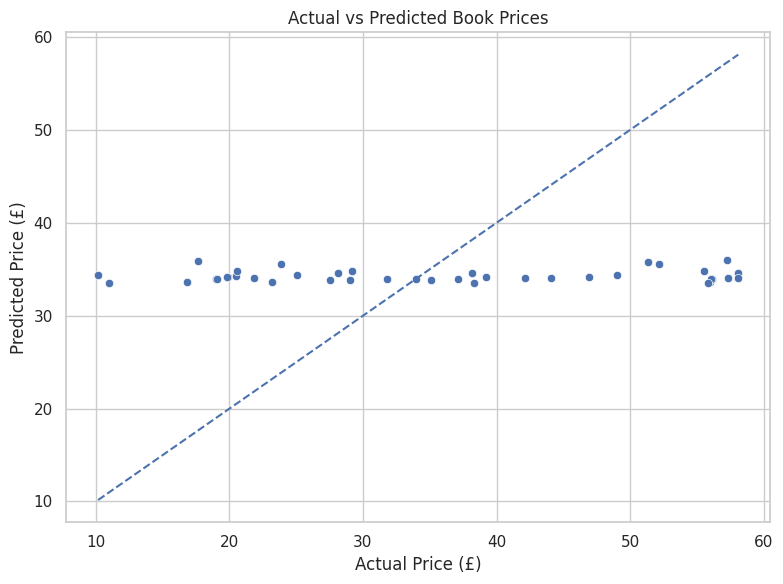

In [20]:

plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_pred)

# Reference line for perfect predictions
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual Price (£)")
plt.ylabel("Predicted Price (£)")
plt.title("Actual vs Predicted Book Prices")
plt.tight_layout()
plt.show()
